In [1]:
from tensorflow.python.lib.io import tf_record
from tensorboard.compat.proto.event_pb2 import Event
from collections import defaultdict
import pandas as pd
import numpy as np
from tensorflow.python.lib.io import tf_record
from tensorboard.compat.proto.event_pb2 import Event
from collections import defaultdict
import pandas as pd
import matplotlib.pyplot as plt

def event_aligned_latency_summary(event_file,
                                  pre_steps=200,
                                  post_steps=2000,
                                  jam_threshold=0.999):

    scalars = defaultdict(list)

    for raw in tf_record.tf_record_iterator(event_file):
        event = Event.FromString(raw)
        if not event.summary:
            continue
        for v in event.summary.value:
            if v.HasField("simple_value"):
                scalars[v.tag].append({
                    "step": event.step,
                    "value": v.simple_value,
                })

    lat = pd.DataFrame(scalars["latency/urllc"]).sort_values("step")
    prb = pd.DataFrame(scalars["prb/effective_ratio"]).sort_values("step")

    df = pd.merge_asof(
        lat, prb,
        on="step",
        direction="nearest",
        tolerance=5,
        suffixes=("_lat", "_prb")
    ).dropna()

    df = df.rename(columns={
        "value_lat": "latency_sec",
        "value_prb": "effective_prb_ratio"
    })

    df["jammed"] = df["effective_prb_ratio"] < jam_threshold

    jam_start_idx = df.index[
        (df["jammed"]) & (~df["jammed"].shift(1).fillna(False))
    ].to_numpy()

    aligned = []

    for idx in jam_start_idx:
        s = idx - pre_steps
        e = idx + post_steps
        if s < 0 or e >= len(df):
            continue
        w = df.iloc[s:e].copy()
        w["t_rel"] = np.arange(-pre_steps, post_steps)
        aligned.append(w[["t_rel", "latency_sec"]])

    aligned_df = pd.concat(aligned)

    summary = (
        aligned_df
        .groupby("t_rel")["latency_sec"]
        .mean()
        .reset_index()
    )

    summary["latency_ms"] = summary["latency_sec"] * 1000.0
    return summary


2026-01-16 14:14:16.318542: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-01-16 14:14:16.348098: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI AVX_VNNI_INT8 AVX_NE_CONVERT FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-01-16 14:14:17.025815: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [2]:
# IDLE_EVENT_FILE = "../tb_logs/res_validator/idle__20260114_104940__res18_off0_const5_per8000_dur2000/events.out.tfevents.1768405780.elahe-LEGION-T7-34IAS10.557366.0"
# RANDOM_EVENT_FILE = "../tb_logs/res_validator/random__20260114_103447__res18_off0_const5_per8000_dur2000/events.out.tfevents.1768404887.elahe-LEGION-T7-34IAS10.555124.0"
# DQN_EVENT_FILE = "../tb_logs/res_validator/xAppResilientDQNAllocator_20260114_145436_step499500__20260114_180159__res18_off0_const5_per8000_dur2000/events.out.tfevents.1768431719.elahe-LEGION-T7-34IAS10.598494.0"

IDLE_EVENT_FILE = "../tb_logs/res_validator/idle__20260115_223343__res18_off0_const5_per8000_dur2000/events.out.tfevents.1768534423.elahe-LEGION-T7-34IAS10.703928.0"
RANDOM_EVENT_FILE = "../tb_logs/res_validator/random__20260115_233825__res18_off0_const5_per8000_dur2000/events.out.tfevents.1768538305.elahe-LEGION-T7-34IAS10.708775.0"
DQN_EVENT_FILE = "../tb_logs/res_validator/xAppResilientDQNAllocator_20260115_234559_final__20260116_093135__res18_off0_const5_per8000_dur2000/events.out.tfevents.1768573895.elahe-LEGION-T7-34IAS10.731660.0"
DQN_EVENT_FILE_2 = "../tb_logs/res_validator/xAppResilientDQNAllocator_20260116_103601_final__20260116_134558__res18_off0_const5_per8000_dur2000/events.out.tfevents.1768589158.elahe-LEGION-T7-34IAS10.749424.0"

idle_summary   = event_aligned_latency_summary(IDLE_EVENT_FILE)
random_summary = event_aligned_latency_summary(RANDOM_EVENT_FILE)
dqn_summary    = event_aligned_latency_summary(DQN_EVENT_FILE)
dqn_summary_2    = event_aligned_latency_summary(DQN_EVENT_FILE_2)


Instructions for updating:
Use eager execution and: 
`tf.data.TFRecordDataset(path)`


/tmp/ipykernel_752167/3044924797.py:49: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  (df["jammed"]) & (~df["jammed"].shift(1).fillna(False))
/tmp/ipykernel_752167/3044924797.py:49: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  (df["jammed"]) & (~df["jammed"].shift(1).fillna(False))
/tmp/ipykernel_752167/3044924797.py:49: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_

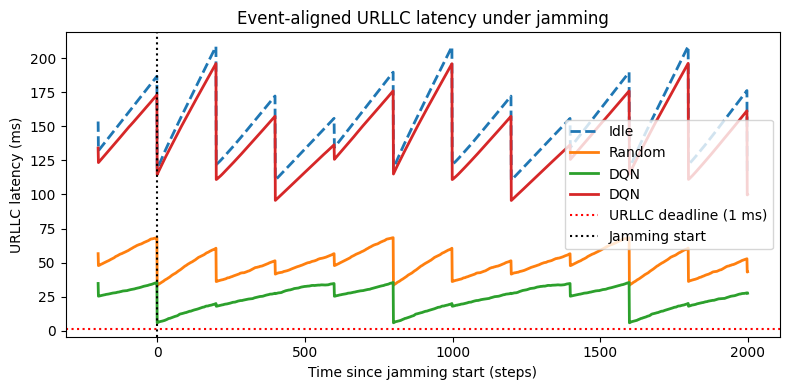

In [3]:
URLLC_DEADLINE_MS = 1.0

plt.figure(figsize=(8, 4))

plt.plot(idle_summary["t_rel"],
         idle_summary["latency_ms"],
         label="Idle",
         linewidth=2,
         linestyle="--")

plt.plot(random_summary["t_rel"],
         random_summary["latency_ms"],
         label="Random",
         linewidth=2)

plt.plot(dqn_summary["t_rel"],
         dqn_summary["latency_ms"],
         label="DQN",
         linewidth=2)

plt.plot(dqn_summary_2["t_rel"],
         dqn_summary_2["latency_ms"],
         label="DQN",
         linewidth=2)


plt.axhline(URLLC_DEADLINE_MS,
            color="red",
            linestyle=":",
            label="URLLC deadline (1 ms)")

plt.axvline(0,
            color="black",
            linestyle=":",
            label="Jamming start")

plt.xlabel("Time since jamming start (steps)")
plt.ylabel("URLLC latency (ms)")
plt.title("Event-aligned URLLC latency under jamming")
plt.legend()
plt.tight_layout()
plt.show()


## Table section

In [17]:
import numpy as np
import pandas as pd
from tensorflow.python.summary.summary_iterator import summary_iterator
def load_tb_scalars(event_file):
    data = {}
    for e in summary_iterator(event_file):
        if not e.summary.value:
            continue
        step = e.step
        for v in e.summary.value:
            tag = v.tag
            data.setdefault(tag, []).append((step, v.simple_value))
    return {
        tag: pd.DataFrame(vals, columns=["step", "value"]).sort_values("step")
        for tag, vals in data.items()
    }
def infer_jamming(effective_prb_ratio, threshold=0.99):
    return effective_prb_ratio["value"] < threshold
def recovery_time(latency, jamming_mask, latency_threshold, hold_steps=10):
    """
    Time from jamming end until latency stays below threshold for hold_steps
    """
    jam_indices = np.where(jamming_mask)[0]
    if len(jam_indices) == 0:
        return np.nan

    jam_end = jam_indices[-1]

    below = latency["value"].values <= latency_threshold
    for i in range(jam_end + 1, len(below) - hold_steps):
        if np.all(below[i:i+hold_steps]):
            return i - jam_end
    return np.inf


In [50]:
URLLC_DEADLINE_MS = 0.001

def evaluate_policy(tb, latency_threshold):

    latency = tb["latency/urllc"]

    eff_prb = tb["prb/effective_ratio"]
    reserve_prb = tb["obs/reserve_used_prb"]
    embb_thr = tb["throughput/embb_mbps"]
    reward = tb["reward/total"]

    jamming = infer_jamming(eff_prb)

    metrics = {}

    # Performance
    metrics["avg_urllc_latency"] = latency["value"].mean()
    metrics["latency_violation_rate"] = np.mean(latency["value"] > latency_threshold)
    metrics["avg_embb_throughput"] = embb_thr["value"].mean()
    metrics["avg_reward"] = reward["value"].mean()

    # Resilience
    metrics["max_latency_spike"] = latency["value"].max()
    metrics["recovery_time"] = recovery_time(
        latency, jamming, latency_threshold
    )
    metrics["avg_reserve_prb_used"] = reserve_prb["value"].mean()

    return metrics


In [51]:
def plot_latency_cdf(lat_ms, label):
    x = np.sort(lat_ms)
    y = np.arange(len(x)) / len(x)
    plt.plot(x, y, label=label)


In [52]:
EVENT_FILES = {
    # "Idle": "../tb_logs/res_validator/idle__20260114_104940__res18_off0_const5_per8000_dur2000/events.out.tfevents.1768405780.elahe-LEGION-T7-34IAS10.557366.0",
    # "Random":"../tb_logs/res_validator/random__20260114_103447__res18_off0_const5_per8000_dur2000/events.out.tfevents.1768404887.elahe-LEGION-T7-34IAS10.555124.0",
    # "DQN": "../tb_logs/res_validator/xAppResilientDQNAllocator_20260114_145436_step499500__20260114_180159__res18_off0_const5_per8000_dur2000/events.out.tfevents.1768431719.elahe-LEGION-T7-34IAS10.598494.0"
    #"Random": "path/to/random/events.out.tfevents...",
    #"DQN": "path/to/dqn/events.out.tfevents..."
    "Idle": IDLE_EVENT_FILE,
    "Random": RANDOM_EVENT_FILE,
    "DQN": DQN_EVENT_FILE
}

LATENCY_DEADLINE_MS = 0.001  # <-- adjust to your setup

rows = []

for name, path in EVENT_FILES.items():
    tb = load_tb_scalars(path)
    metrics = evaluate_policy(tb, LATENCY_DEADLINE_MS)
    metrics["policy"] = name
    rows.append(metrics)

df = pd.DataFrame(rows).set_index("policy")


In [53]:
df.to_csv("table_main_results.csv")
print(df)

        avg_urllc_latency  latency_violation_rate  avg_embb_throughput  \
policy                                                                   
Idle              0.15552                0.409750            94.616798   
Random            0.05170                0.203323            95.271696   
DQN               0.02376                0.184324            95.177791   

        avg_reward  max_latency_spike  recovery_time  avg_reserve_prb_used  
policy                                                                      
Idle     -2.480419           2.091662            inf              0.000000  
Random   -1.463533           1.175349            inf             11.702783  
DQN      -0.850496           1.693525            inf             15.373333  


In [54]:
JAM_THRESHOLD = 0.99          # effective PRB ratio < threshold ⇒ jamming
URLLC_LATENCY_DEADLINE = 0.001  # ms (adjust if needed)
RECOVERY_HOLD_STEPS = 10


In [55]:
import numpy as np
import pandas as pd
from tensorflow.python.summary.summary_iterator import summary_iterator
def load_tb_scalars(event_file):
    data = {}
    for e in summary_iterator(event_file):
        if not e.summary.value:
            continue
        for v in e.summary.value:
            data.setdefault(v.tag, []).append((e.step, v.simple_value))
    return {
        tag: pd.DataFrame(vals, columns=["step", "value"]).sort_values("step")
        for tag, vals in data.items()
    }

def align_on_step(dfs):
    base = dfs[0][["step"]].copy()
    for df in dfs:
        base = base.merge(df, on="step", how="inner")
    return base
def jamming_mask(effective_prb_ratio):
    return effective_prb_ratio["value"] < JAM_THRESHOLD


In [56]:
def table_performance(tb):
    return {
        "avg_urllc_latency": tb["latency/urllc"]["value"].mean(),
        "latency_violation_rate": np.mean(
            tb["latency/urllc"]["value"] > URLLC_LATENCY_DEADLINE
        ),
        "avg_embb_throughput": tb["throughput/embb_mbps"]["value"].mean(),
        "avg_reward": tb["reward/total"]["value"].mean(),
    }


In [57]:
def recovery_time(latency, jam_mask):
    jam_idx = np.where(jam_mask)[0]
    if len(jam_idx) == 0:
        return np.nan
    jam_end = jam_idx[-1]

    below = latency["value"].values <= URLLC_LATENCY_DEADLINE
    for i in range(jam_end + 1, len(below) - RECOVERY_HOLD_STEPS):
        if np.all(below[i:i+RECOVERY_HOLD_STEPS]):
            return i - jam_end
    return np.inf


In [58]:
def table_resilience(tb):
    eff = tb["prb/effective_ratio"]
    jam = jamming_mask(eff)
    lat = tb["latency/urllc"]

    return {
        "max_latency_spike": lat["value"].max(),
        "recovery_time": recovery_time(lat, jam),
        "avg_reserve_prb_used": tb["obs/reserve_used_prb"]["value"].mean(),
    }


In [59]:
STATE_TAGS = [
    "state/embb_demand_norm",
    "state/urllc_demand_norm",
    "state/embb_queue_norm",
    "state/urllc_queue_norm",
    "state/embb_thr_norm",
    "state/urllc_thr_norm",
    "state/urllc_lat_excess_norm",
    "state/effective_prb_ratio",
    "state/reserve_used_norm",
]


In [60]:
def table_state_stats(tb):
    row = {}
    for tag in STATE_TAGS:
        v = tb[tag]["value"]
        row[f"{tag}_mean"] = v.mean()
        row[f"{tag}_std"] = v.std()
    return row


In [61]:
def table_jamming_split(tb):
    eff = tb["prb/effective_ratio"]
    jam = jamming_mask(eff)

    lat = tb["latency/urllc"]["value"]
    q = tb["obs/urllc_queue"]["value"]
    r = tb["obs/reserve_used_prb"]["value"]

    return {
        "lat_no_jam": lat[~jam].mean(),
        "lat_jam": lat[jam].mean(),
        "delta_latency": lat[jam].mean() - lat[~jam].mean(),
        "reserve_used_jam": r[jam].mean(),
        "queue_jam": q[jam].mean(),
    }


In [62]:
def table_reserve_efficiency(tb):
    eff = tb["prb/effective_ratio"]
    jam = jamming_mask(eff)
    lat = tb["latency/urllc"]["value"]
    r = tb["obs/reserve_used_prb"]["value"]

    violations = np.mean(lat[jam] > URLLC_LATENCY_DEADLINE)
    return {
        "reserve_used_jam": r[jam].mean(),
        "violation_rate_jam": violations,
        "max_latency_jam": lat[jam].max(),
    }


In [63]:
def table_actions(tb):
    a = tb["action/index"]["value"]
    da = np.abs(np.diff(a))

    return {
        "action_variance": a.var(),
        "action_change_rate": np.mean(da > 0),
        "mean_abs_action_change": da.mean(),
    }


In [64]:
def table_satisfaction(tb):
    return {
        "urllc_sat_capped": tb["satisfaction/URLLC_capped"]["value"].mean(),
        "embb_sat_capped": tb["satisfaction/eMBB_capped"]["value"].mean(),
        "urllc_sat_worst": tb["satisfaction/URLLC_raw"]["value"].min(),
    }


In [65]:
def table_episode(tb):
    r = tb["episode/return"]["value"]
    l = tb["episode/length"]["value"]

    return {
        "return_mean": r.mean(),
        "return_std": r.std(),
        "return_p10": np.percentile(r, 10),
        "episode_length_mean": l.mean(),
    }


In [66]:
def table_correlation(tb):
    eff = tb["prb/effective_ratio"]
    jam = jamming_mask(eff)

    lat = tb["latency/urllc"]["value"][jam]
    q = tb["state/urllc_queue_norm"]["value"][jam]
    r = tb["state/reserve_used_norm"]["value"][jam]

    return {
        "corr_queue_latency": np.corrcoef(q, lat)[0,1],
        "corr_reserve_latency": np.corrcoef(r, lat)[0,1],
    }


In [67]:
def print_table(name, df, float_fmt="{:.3f}"):
    print("\n" + "=" * 80)
    print(f"TABLE: {name.upper()}")
    print("=" * 80)
    print(df.to_string(float_format=lambda x: float_fmt.format(x)))


In [69]:
# EVENTS = {
#     # "Idle": "path/to/idle/events",
#     # "Random": "path/to/random/events",
#     "Idle": "../tb_logs/res_validator/idle__20260114_104940__res18_off0_const5_per8000_dur2000/events.out.tfevents.1768405780.elahe-LEGION-T7-34IAS10.557366.0",
#     "Random":"../tb_logs/res_validator/random__20260114_103447__res18_off0_const5_per8000_dur2000/events.out.tfevents.1768404887.elahe-LEGION-T7-34IAS10.555124.0",
#     "DQN": "../tb_logs/res_validator/xAppResilientDQNAllocator_20260114_145436_step499500__20260114_180159__res18_off0_const5_per8000_dur2000/events.out.tfevents.1768431719.elahe-LEGION-T7-34IAS10.598494.0"
#     #"DQN": "path/to/dqn/events",
    
# }
EVENTS = {
    # "Idle": "../tb_logs/res_validator/idle__20260114_104940__res18_off0_const5_per8000_dur2000/events.out.tfevents.1768405780.elahe-LEGION-T7-34IAS10.557366.0",
    # "Random":"../tb_logs/res_validator/random__20260114_103447__res18_off0_const5_per8000_dur2000/events.out.tfevents.1768404887.elahe-LEGION-T7-34IAS10.555124.0",
    # "DQN": "../tb_logs/res_validator/xAppResilientDQNAllocator_20260114_145436_step499500__20260114_180159__res18_off0_const5_per8000_dur2000/events.out.tfevents.1768431719.elahe-LEGION-T7-34IAS10.598494.0"
    #"Random": "path/to/random/events.out.tfevents...",
    #"DQN": "path/to/dqn/events.out.tfevents..."
    "Idle": IDLE_EVENT_FILE,
    "Random": RANDOM_EVENT_FILE,
    "DQN": DQN_EVENT_FILE
}

LATENCY_DEADLINE_MS = 0.001  # <-- adjust to your setup




tables = {
    "performance": [],
    "resilience": [],
    "state_stats": [],
    "jamming_split": [],
    "reserve_efficiency": [],
    "actions": [],
    "satisfaction": [],
    "episode": [],
    "correlation": [],
}

for name, path in EVENTS.items():
    tb = load_tb_scalars(path)

    for key, fn in [
        ("performance", table_performance),
        ("resilience", table_resilience),
        ("state_stats", table_state_stats),
        ("jamming_split", table_jamming_split),
        ("reserve_efficiency", table_reserve_efficiency),
        ("actions", table_actions),
        ("satisfaction", table_satisfaction),
        ("episode", table_episode),
        ("correlation", table_correlation),
    ]:
        row = fn(tb)
        row["policy"] = name
        tables[key].append(row)

for k, rows in tables.items():
    df = pd.DataFrame(rows).set_index("policy")
    df.to_csv(f"table_{k}.csv")
    
    # Print to console
    print_table(k, df)


/home/elahe/anaconda3/envs/airansim/lib/python3.12/site-packages/numpy/lib/_function_base_impl.py:3045: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/home/elahe/anaconda3/envs/airansim/lib/python3.12/site-packages/numpy/lib/_function_base_impl.py:3046: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]



TABLE: PERFORMANCE
        avg_urllc_latency  latency_violation_rate  avg_embb_throughput  avg_reward
policy                                                                            
Idle                0.156                   0.410               94.617      -2.480
Random              0.052                   0.203               95.272      -1.464
DQN                 0.024                   0.184               95.178      -0.850

TABLE: RESILIENCE
        max_latency_spike  recovery_time  avg_reserve_prb_used
policy                                                        
Idle                2.092            inf                 0.000
Random              1.175            inf                11.703
DQN                 1.694            inf                15.373

TABLE: STATE_STATS
        state/embb_demand_norm_mean  state/embb_demand_norm_std  state/urllc_demand_norm_mean  state/urllc_demand_norm_std  state/embb_queue_norm_mean  state/embb_queue_norm_std  state/urllc_queue_norm_mean  sta

## This part would be sufficient (for tables) beside the first plot

In [38]:
import numpy as np
import pandas as pd
from tensorflow.python.summary.summary_iterator import summary_iterator

# ========== LATENCY UNITS CONFIGURATION ==========
# Set LATENCY_UNIT to "sec" or "ms"
LATENCY_UNIT = "both"  # Options: "sec", "ms", or "both"

# When unit is "sec": values are in seconds (0.001, 0.002, ...)
# When unit is "ms": values are in milliseconds (1.0, 2.0, ...)
URLLC_LATENCY_DEADLINE_SEC = 0.001   # 1 ms in seconds
URLLC_LATENCY_DEADLINE_MS = 1.0      # 1 ms

# For dynamic selection
URLLC_LATENCY_DEADLINE = {
    "sec": URLLC_LATENCY_DEADLINE_SEC,
    "ms": URLLC_LATENCY_DEADLINE_MS,
}

JAM_THRESHOLD = 0.99
RECOVERY_HOLD_STEPS = 10
FLOAT_FMT = "{:.3f}"


def load_tb_scalars(event_file):
    data = {}
    for e in summary_iterator(event_file):
        if not e.summary.value:
            continue
        for v in e.summary.value:
            data.setdefault(v.tag, []).append((e.step, v.simple_value))

    return {
        tag: pd.DataFrame(vals, columns=["step", "value"]).sort_values("step")
        for tag, vals in data.items()
    }

def has_tags(tb, tags):
    return all(tag in tb for tag in tags)


def print_table(name, df, unit=""):
    unit_str = f" ({unit})" if unit else ""
    print("\n" + "=" * 90)
    print(f"TABLE: {name.upper()}{unit_str}")
    print("=" * 90)
    print(df.to_string(float_format=lambda x: FLOAT_FMT.format(x)))


def recovery_time(lat, jam_mask, deadline):
    """Time from jamming end until latency stays below deadline for hold_steps"""
    idx = np.where(jam_mask)[0]
    if len(idx) == 0:
        return np.nan

    jam_end = idx[-1]
    below = lat <= deadline

    for i in range(jam_end + 1, len(below) - RECOVERY_HOLD_STEPS):
        if np.all(below[i:i + RECOVERY_HOLD_STEPS]):
            return i - jam_end

    return np.inf


# ========== SECONDS-BASED TABLE FUNCTIONS ==========

def table_performance_sec(tb):
    required = [
        "latency/urllc",
        "throughput/embb_mbps",
        "reward/total",
    ]
    if not has_tags(tb, required):
        return None

    lat = tb["latency/urllc"]["value"]  # in seconds
    thr = tb["throughput/embb_mbps"]["value"]
    rew = tb["reward/total"]["value"]

    return {
        "avg_urllc_latency": lat.mean(),
        "latency_violation_rate": np.mean(lat > URLLC_LATENCY_DEADLINE["sec"]),
        "avg_embb_throughput": thr.mean(),
        "avg_reward": rew.mean(),
    }


def table_resilience_sec(tb):
    required = [
        "latency/urllc",
        "prb/effective_ratio",
        "obs/reserve_used_prb",
    ]
    if not has_tags(tb, required):
        return None

    df = tb["latency/urllc"].merge(
        tb["prb/effective_ratio"], on="step", how="inner"
    )

    lat = df["value_x"].values
    jam = df["value_y"].values < JAM_THRESHOLD

    return {
        "max_latency_spike": lat.max(),
        "recovery_time": recovery_time(lat, jam, URLLC_LATENCY_DEADLINE["sec"]),
        "avg_reserve_prb_used": tb["obs/reserve_used_prb"]["value"].mean(),
    }


def table_jamming_split_sec(tb):
    required = [
        "latency/urllc",
        "prb/effective_ratio",
        "obs/urllc_queue",
        "obs/reserve_used_prb",
    ]
    if not has_tags(tb, required):
        return None

    df = (
        tb["latency/urllc"]
        .merge(tb["prb/effective_ratio"], on="step", how="inner")
        .merge(tb["obs/urllc_queue"], on="step", how="inner")
    )

    lat = df["value_x"]
    jam = df["value_y"] < JAM_THRESHOLD
    queue = df["value"]

    r = tb["obs/reserve_used_prb"]["value"]

    return {
        "lat_no_jam": lat[~jam].mean(),
        "lat_jam": lat[jam].mean(),
        "delta_latency": lat[jam].mean() - lat[~jam].mean(),
        "queue_jam": queue[jam].mean(),
        "reserve_used_jam": r.mean(),
    }


def table_reserve_efficiency_sec(tb):
    required = [
        "latency/urllc",
        "prb/effective_ratio",
        "obs/reserve_used_prb",
    ]
    if not has_tags(tb, required):
        return None

    df = tb["latency/urllc"].merge(
        tb["prb/effective_ratio"], on="step", how="inner"
    )

    lat = df["value_x"]
    jam = df["value_y"] < JAM_THRESHOLD
    r = tb["obs/reserve_used_prb"]["value"]

    violations = np.mean(lat[jam] > URLLC_LATENCY_DEADLINE["sec"])
    return {
        "reserve_used_jam": r.mean(),
        "violation_rate_jam": violations,
        "max_latency_jam": lat[jam].max(),
    }


# ========== MILLISECONDS-BASED TABLE FUNCTIONS ==========

def table_performance_ms(tb):
    required = [
        "latency/urllc",
        "throughput/embb_mbps",
        "reward/total",
    ]
    if not has_tags(tb, required):
        return None

    lat = tb["latency/urllc"]["value"] * 1000.0  # Convert to ms
    thr = tb["throughput/embb_mbps"]["value"]
    rew = tb["reward/total"]["value"]

    return {
        "avg_urllc_latency": lat.mean(),
        "latency_violation_rate": np.mean(lat > URLLC_LATENCY_DEADLINE["ms"]),
        "avg_embb_throughput": thr.mean(),
        "avg_reward": rew.mean(),
    }


def table_resilience_ms(tb):
    required = [
        "latency/urllc",
        "prb/effective_ratio",
        "obs/reserve_used_prb",
    ]
    if not has_tags(tb, required):
        return None

    df = tb["latency/urllc"].merge(
        tb["prb/effective_ratio"], on="step", how="inner"
    )

    lat = df["value_x"].values * 1000.0  # Convert to ms
    jam = df["value_y"].values < JAM_THRESHOLD

    return {
        "max_latency_spike": lat.max(),
        "recovery_time": recovery_time(lat, jam, URLLC_LATENCY_DEADLINE["ms"]),
        "avg_reserve_prb_used": tb["obs/reserve_used_prb"]["value"].mean(),
    }


def table_jamming_split_ms(tb):
    required = [
        "latency/urllc",
        "prb/effective_ratio",
        "obs/urllc_queue",
        "obs/reserve_used_prb",
    ]
    if not has_tags(tb, required):
        return None

    df = (
        tb["latency/urllc"]
        .merge(tb["prb/effective_ratio"], on="step", how="inner")
        .merge(tb["obs/urllc_queue"], on="step", how="inner")
    )

    lat = df["value_x"] * 1000.0  # Convert to ms
    jam = df["value_y"] < JAM_THRESHOLD
    queue = df["value"]

    r = tb["obs/reserve_used_prb"]["value"]

    return {
        "lat_no_jam": lat[~jam].mean(),
        "lat_jam": lat[jam].mean(),
        "delta_latency": lat[jam].mean() - lat[~jam].mean(),
        "queue_jam": queue[jam].mean(),
        "reserve_used_jam": r.mean(),
    }


def table_reserve_efficiency_ms(tb):
    required = [
        "latency/urllc",
        "prb/effective_ratio",
        "obs/reserve_used_prb",
    ]
    if not has_tags(tb, required):
        return None

    df = tb["latency/urllc"].merge(
        tb["prb/effective_ratio"], on="step", how="inner"
    )

    lat = df["value_x"] * 1000.0  # Convert to ms
    jam = df["value_y"] < JAM_THRESHOLD
    r = tb["obs/reserve_used_prb"]["value"]

    violations = np.mean(lat[jam] > URLLC_LATENCY_DEADLINE["ms"])
    return {
        "reserve_used_jam": r.mean(),
        "violation_rate_jam": violations,
        "max_latency_jam": lat[jam].max(),
    }


In [39]:
STATE_TAGS = [
    "state/embb_demand_norm",
    "state/urllc_demand_norm",
    "state/embb_queue_norm",
    "state/urllc_queue_norm",
    "state/embb_thr_norm",
    "state/urllc_thr_norm",
    "state/urllc_lat_excess_norm",
    "state/effective_prb_ratio",
    "state/reserve_used_norm",
]

def table_state_stats(tb):
    """Unit-agnostic: returns state statistics"""
    if not has_tags(tb, STATE_TAGS):
        return None

    row = {}
    for tag in STATE_TAGS:
        v = tb[tag]["value"]
        row[f"{tag}_mean"] = v.mean()
        row[f"{tag}_std"] = v.std()
    return row

def table_actions(tb):
    """Unit-agnostic: returns action statistics"""
    if "action/index" not in tb:
        return None
    
    a = tb["action/index"]["value"]
    da = np.abs(np.diff(a))

    return {
        "action_variance": a.var(),
        "action_change_rate": np.mean(da > 0),
        "mean_abs_action_change": da.mean(),
    }

def table_satisfaction(tb):
    """Unit-agnostic: returns satisfaction metrics"""
    required = ["satisfaction/URLLC_capped", "satisfaction/eMBB_capped", "satisfaction/URLLC_raw"]
    if not has_tags(tb, required):
        return None
    
    return {
        "urllc_sat_capped": tb["satisfaction/URLLC_capped"]["value"].mean(),
        "embb_sat_capped": tb["satisfaction/eMBB_capped"]["value"].mean(),
        "urllc_sat_worst": tb["satisfaction/URLLC_raw"]["value"].min(),
    }

def table_episode(tb):
    """Unit-agnostic: returns episode statistics"""
    required = ["episode/return", "episode/length"]
    if not has_tags(tb, required):
        return None
    
    r = tb["episode/return"]["value"]
    l = tb["episode/length"]["value"]

    return {
        "return_mean": r.mean(),
        "return_std": r.std(),
        "return_p10": np.percentile(r, 10),
        "episode_length_mean": l.mean(),
    }

def table_correlation(tb):
    """Unit-agnostic: returns correlation metrics"""
    required = [
        "latency/urllc",
        "prb/effective_ratio",
        "state/urllc_queue_norm",
        "state/reserve_used_norm",
    ]
    if not has_tags(tb, required):
        return None

    df = tb["latency/urllc"].merge(
        tb["prb/effective_ratio"], on="step", how="inner"
    )

    jam = df["value_y"] < JAM_THRESHOLD
    lat = df["value_x"][jam]

    df2 = (
        tb["state/urllc_queue_norm"]
        .merge(tb["state/reserve_used_norm"], on="step", how="inner")
    )
    q = df2["value_x"][jam]
    r = df2["value_y"][jam]

    return {
        "corr_queue_latency": np.corrcoef(q, lat)[0, 1],
        "corr_reserve_latency": np.corrcoef(r, lat)[0, 1],
    }


In [40]:
def table_state_stats(tb):
    if not has_tags(tb, STATE_TAGS):
        return None

    row = {}
    for tag in STATE_TAGS:
        v = tb[tag]["value"]
        row[f"{tag}_mean"] = v.mean()
        row[f"{tag}_std"] = v.std()
    return row

def table_jamming_split(tb):
    required = [
        "latency/urllc",
        "prb/effective_ratio",
        "obs/urllc_queue",
        "obs/reserve_used_prb",
    ]
    if not has_tags(tb, required):
        return None

    df = (
        tb["latency/urllc"]
        .merge(tb["prb/effective_ratio"], on="step", how="inner")
        .merge(tb["obs/urllc_queue"], on="step", how="inner")
    )

    lat = df["value_x"]
    jam = df["value_y"] < JAM_THRESHOLD
    queue = df["value"]

    r = tb["obs/reserve_used_prb"]["value"]

    return {
        "lat_no_jam": lat[~jam].mean(),
        "lat_jam": lat[jam].mean(),
        "delta_latency": lat[jam].mean() - lat[~jam].mean(),
        "queue_jam": queue[jam].mean(),
        "reserve_used_jam": r.mean(),
    }


In [41]:
def table_embb_throughput(tb):
    if "throughput/embb_mbps" not in tb:
        return None

    v = tb["throughput/embb_mbps"]["value"]
    return {
        "embb_thr_mean": v.mean(),
        "embb_thr_std": v.std(),
    }
def table_embb_jam_split(tb):
    required = [
        "throughput/embb_mbps",
        "prb/effective_ratio",
    ]
    if not has_tags(tb, required):
        return None

    df = tb["throughput/embb_mbps"].merge(
        tb["prb/effective_ratio"], on="step", how="inner"
    )

    thr = df["value_x"]
    jam = df["value_y"] < JAM_THRESHOLD

    return {
        "embb_thr_no_jam": thr[~jam].mean(),
        "embb_thr_jam": thr[jam].mean(),
        "embb_thr_drop": thr[jam].mean() - thr[~jam].mean(),
    }

def table_embb_efficiency(tb):
    required = [
        "obs/embb_throughput",
        "obs/embb_base_achievable_throughput",
        "prb/effective_ratio",
    ]
    if not has_tags(tb, required):
        return None

    df = (
        tb["obs/embb_throughput"]
        .merge(tb["obs/embb_base_achievable_throughput"], on="step", how="inner")
        .merge(tb["prb/effective_ratio"], on="step", how="inner")
    )

    thr = df["value_x"]
    base = df["value_y"]
    eff = thr / np.maximum(base, 1e-6)
    jam = df["value"] < JAM_THRESHOLD

    return {
        "embb_eff_mean": eff.mean(),
        "embb_eff_jam": eff[jam].mean(),
    }

def table_embb_state(tb):
    if "state/embb_thr_norm" not in tb:
        return None

    v = tb["state/embb_thr_norm"]["value"]
    return {
        "embb_thr_norm_mean": v.mean(),
        "embb_thr_norm_std": v.std(),
    }


In [42]:
# EVENTS = {
#     # "Idle":   "path/to/idle/events.out.tfevents...",
#     # "Random": "path/to/random/events.out.tfevents...",
#     "Idle": "../tb_logs/res_validator/idle__20260115_071424__res18_off0_const5_per8000_dur2000/events.out.tfevents.1768479264.elahe-LEGION-T7-34IAS10.631069.0",
#     #"Idle": "../tb_logs/res_validator/idle__20260114_104940__res18_off0_const5_per8000_dur2000/events.out.tfevents.1768405780.elahe-LEGION-T7-34IAS10.557366.0",
#     #"Random":"../tb_logs/res_validator/random__20260114_103447__res18_off0_const5_per8000_dur2000/events.out.tfevents.1768404887.elahe-LEGION-T7-34IAS10.555124.0",
#     "Random":"../tb_logs/res_validator/random__20260115_065759__res18_off0_const5_per8000_dur2000/events.out.tfevents.1768478279.elahe-LEGION-T7-34IAS10.629126.0",
#     #"DQN": "../tb_logs/res_validator/xAppResilientDQNAllocator_20260114_145436_step499500__20260114_180159__res18_off0_const5_per8000_dur2000/events.out.tfevents.1768431719.elahe-LEGION-T7-34IAS10.598494.0"
#     "DQN": "../tb_logs/res_validator/xAppResilientDQNAllocator_20260115_072913_step499500__20260115_103027__res18_off0_const5_per8000_dur2000/events.out.tfevents.1768491027.elahe-LEGION-T7-34IAS10.647962.0"
#     #"DQN":    "path/to/dqn/events.out.tfevents...",
# }


# Table functions: (name, sec_function, ms_function, unit_agnostic)
# If unit_agnostic=True, only one function is needed
TABLE_CONFIGS = [
    ("performance", table_performance_sec, table_performance_ms, False),
    ("resilience", table_resilience_sec, table_resilience_ms, False),
    ("jamming_split", table_jamming_split_sec, table_jamming_split_ms, False),
    ("reserve_efficiency", table_reserve_efficiency_sec, table_reserve_efficiency_ms, False),
    ("state_stats", table_state_stats, None, True),
    ("actions", table_actions, None, True),
    ("satisfaction", table_satisfaction, None, True),
    ("episode", table_episode, None, True),
    ("correlation", table_correlation, None, True),
]

# Generate tables for both units
tables_sec = {name: [] for name, _, _, _ in TABLE_CONFIGS}
tables_ms = {name: [] for name, _, _, _ in TABLE_CONFIGS}

for policy, path in EVENTS.items():
    tb = load_tb_scalars(path)

    for name, fn_sec, fn_ms, is_agnostic in TABLE_CONFIGS:
        if is_agnostic:
            # Unit-agnostic: generate once
            row = fn_sec(tb)
            if row is not None:
                row["policy"] = policy
                tables_sec[name].append(row)
                tables_ms[name].append(row.copy())
        else:
            # Unit-specific: generate for both sec and ms
            row_sec = fn_sec(tb)
            row_ms = fn_ms(tb)
            
            if row_sec is not None:
                row_sec["policy"] = policy
                tables_sec[name].append(row_sec)
            
            if row_ms is not None:
                row_ms["policy"] = policy
                tables_ms[name].append(row_ms)


/home/elahe/anaconda3/envs/airansim/lib/python3.12/site-packages/numpy/lib/_function_base_impl.py:3045: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/home/elahe/anaconda3/envs/airansim/lib/python3.12/site-packages/numpy/lib/_function_base_impl.py:3046: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


In [43]:
print("\n\n" + "="*100)
print("GENERATING TABLES FOR SECONDS")
print("="*100)

for name, rows in tables_sec.items():
    if len(rows) == 0:
        print(f"[WARN] Table '{name}' is empty — skipped")
        continue

    df = pd.DataFrame(rows).set_index("policy")
    df.to_csv(f"table_{name}_sec.csv")
    print_table(name, df, unit="seconds")

print("\n\n" + "="*100)
print("GENERATING TABLES FOR MILLISECONDS")
print("="*100)

for name, rows in tables_ms.items():
    if len(rows) == 0:
        print(f"[WARN] Table '{name}' is empty — skipped")
        continue

    df = pd.DataFrame(rows).set_index("policy")
    df.to_csv(f"table_{name}_ms.csv")
    print_table(name, df, unit="milliseconds")




GENERATING TABLES FOR SECONDS

TABLE: PERFORMANCE (seconds)
        avg_urllc_latency  latency_violation_rate  avg_embb_throughput  avg_reward
policy                                                                            
Idle                0.156                   0.410               94.617      -2.480
Random              0.052                   0.203               95.272      -1.464
DQN                 0.024                   0.184               95.178      -0.850

TABLE: RESILIENCE (seconds)
        max_latency_spike  recovery_time  avg_reserve_prb_used
policy                                                        
Idle                2.092            inf                 0.000
Random              1.175            inf                11.703
DQN                 1.694            inf                15.373

TABLE: JAMMING_SPLIT (seconds)
        lat_no_jam  lat_jam  delta_latency  queue_jam  reserve_used_jam
policy                                                                 
Idl

### Figures

In [44]:
import matplotlib.pyplot as plt
def align_tags(tb, tags):
    dfs = [tb[tag] for tag in tags]
    base = dfs[0]
    for df in dfs[1:]:
        base = base.merge(df, on="step", how="inner")
    return base


def shade_jamming(ax, steps, eff_ratio, threshold=JAM_THRESHOLD):
    jam = eff_ratio < threshold
    in_jam = False
    start = None

    for i, j in enumerate(jam):
        if j and not in_jam:
            start = steps[i]
            in_jam = True
        elif not j and in_jam:
            ax.axvspan(start, steps[i], alpha=0.2)
            in_jam = False

    if in_jam:
        ax.axvspan(start, steps[-1], alpha=0.2)


In [45]:
def plot_urllc_latency(EVENTS, unit="sec"):
    """
    Plot URLLC latency over time.
    unit: "sec" (seconds) or "ms" (milliseconds)
    """
    conversion = 1000.0 if unit == "ms" else 1.0
    deadline = URLLC_LATENCY_DEADLINE[unit]
    
    plt.figure(figsize=(8, 4))

    for policy, path in EVENTS.items():
        tb = load_tb_scalars(path)

        df = align_tags(tb, [
            "latency/urllc",
            "prb/effective_ratio"
        ])

        plt.plot(
            df["step"],
            df["value_x"] * conversion,
            label=policy,
            linewidth=1.8
        )

    # Shade jamming using one reference
    ref_tb = load_tb_scalars(list(EVENTS.values())[0])
    ref_df = align_tags(ref_tb, [
        "latency/urllc",
        "prb/effective_ratio"
    ])
    shade_jamming(plt.gca(), ref_df["step"], ref_df["value_y"])

    plt.axhline(
        deadline,
        linestyle="--",
        linewidth=1.2,
        label="Latency deadline"
    )

    unit_label = "ms" if unit == "ms" else "seconds"
    plt.xlabel("Time step")
    plt.ylabel(f"URLLC latency ({unit_label})")
    plt.title(f"URLLC latency over time ({unit_label})")
    plt.legend()
    plt.tight_layout()
    plt.show()


In [46]:
def plot_reserve_prb(EVENTS):
    plt.figure(figsize=(6, 3))

    for policy, path in EVENTS.items():
        tb = load_tb_scalars(path)

        df = align_tags(tb, [
            "obs/reserve_used_prb",
            "prb/effective_ratio"
        ])

        plt.plot(
            df["step"],
            df["value_x"],
            label=policy,
            linewidth=1.8
        )

    ref_tb = load_tb_scalars(list(EVENTS.values())[0])
    ref_df = align_tags(ref_tb, [
        "obs/reserve_used_prb",
        "prb/effective_ratio"
    ])
    shade_jamming(plt.gca(), ref_df["step"], ref_df["value_y"])

    plt.xlabel("Time step")
    plt.ylabel("Reserved PRBs used")
    plt.legend()
    plt.tight_layout()
    plt.show()


In [47]:
def plot_embb_throughput(EVENTS):
    plt.figure(figsize=(6, 3))

    for policy, path in EVENTS.items():
        tb = load_tb_scalars(path)

        df = align_tags(tb, [
            "throughput/embb_mbps",
            "prb/effective_ratio"
        ])

        plt.plot(
            df["step"],
            df["value_x"],
            label=policy,
            linewidth=1.8
        )

    ref_tb = load_tb_scalars(list(EVENTS.values())[0])
    ref_df = align_tags(ref_tb, [
        "throughput/embb_mbps",
        "prb/effective_ratio"
    ])
    shade_jamming(plt.gca(), ref_df["step"], ref_df["value_y"])

    plt.xlabel("Time step")
    plt.ylabel("eMBB throughput (Mbps)")
    plt.legend()
    plt.tight_layout()
    plt.show()


In [48]:
def plot_effective_prb(EVENTS):
    plt.figure(figsize=(6, 2.5))

    for policy, path in EVENTS.items():
        tb = load_tb_scalars(path)
        df = tb["prb/effective_ratio"]

        plt.plot(
            df["step"],
            df["value"],
            label=policy,
            linewidth=1.5
        )

    plt.axhline(1.0, linestyle="--", linewidth=1.0)
    plt.xlabel("Time step")
    plt.ylabel("Effective PRB ratio")
    plt.legend()
    plt.tight_layout()
    plt.show()



PLOTS FOR SECONDS


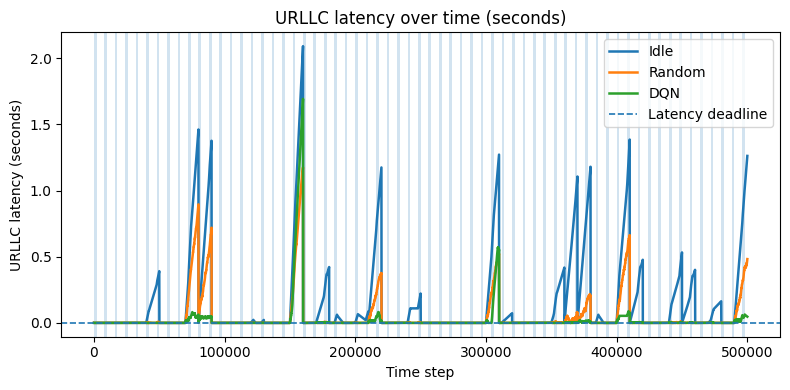

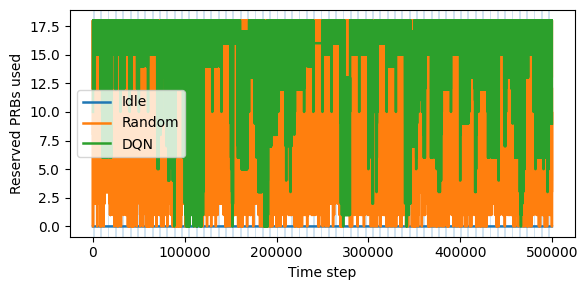

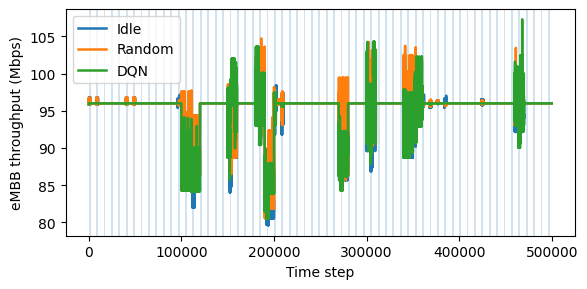

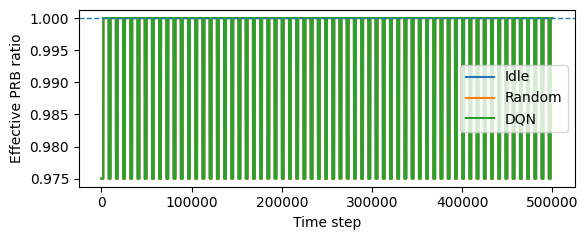


PLOTS FOR MILLISECONDS


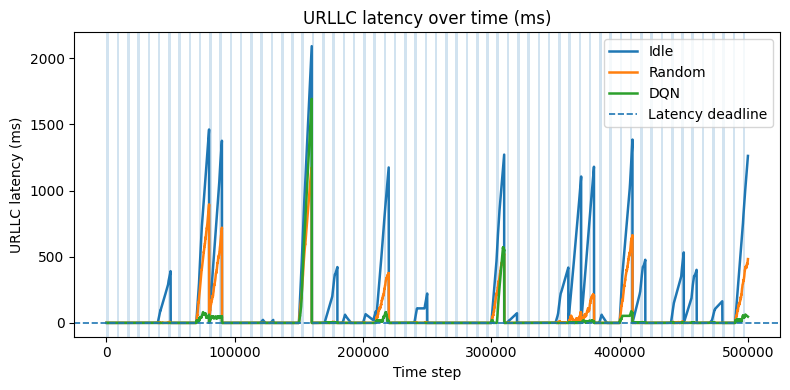

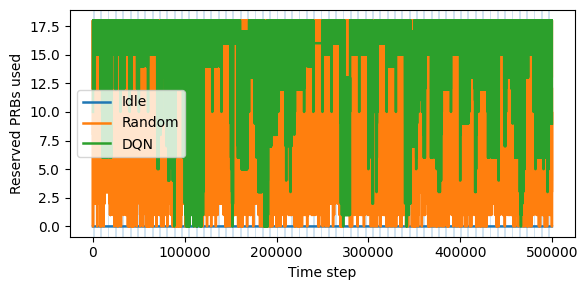

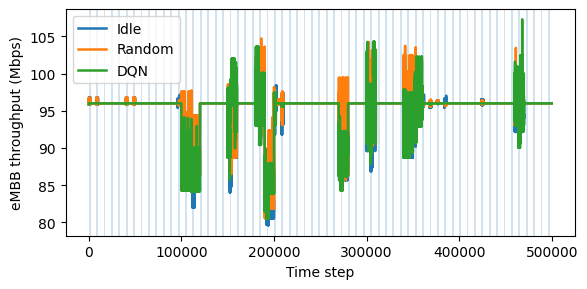

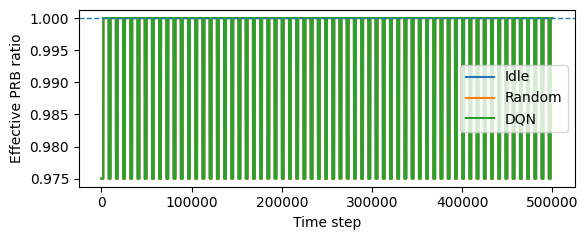

In [49]:
print("\n" + "="*100)
print("PLOTS FOR SECONDS")
print("="*100)
plot_urllc_latency(EVENTS, unit="sec")
plot_reserve_prb(EVENTS)
plot_embb_throughput(EVENTS)
plot_effective_prb(EVENTS)

print("\n" + "="*100)
print("PLOTS FOR MILLISECONDS")
print("="*100)
plot_urllc_latency(EVENTS, unit="ms")
plot_reserve_prb(EVENTS)
plot_embb_throughput(EVENTS)
plot_effective_prb(EVENTS)
